In [6]:
print("CodeAlpha Iris Classification Started!")

from sklearn.datasets import load_iris

iris = load_iris()

print("Dataset loaded successfully!")
print("Total samples:", len(iris.data))
print("Features:", iris.feature_names)

CodeAlpha Iris Classification Started!
Dataset loaded successfully!
Total samples: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df["species"] = iris.target

# Convert numerical labels into species names
df["species_name"] = df["species"].map(
    dict(enumerate(iris.target_names))
)

# Display first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [9]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])



Dataset Shape: (150, 6)
Total Rows: 150
Total Columns: 6


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [11]:
df.describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [12]:
print(df["species_name"].value_counts())

species_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [13]:
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64


In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1


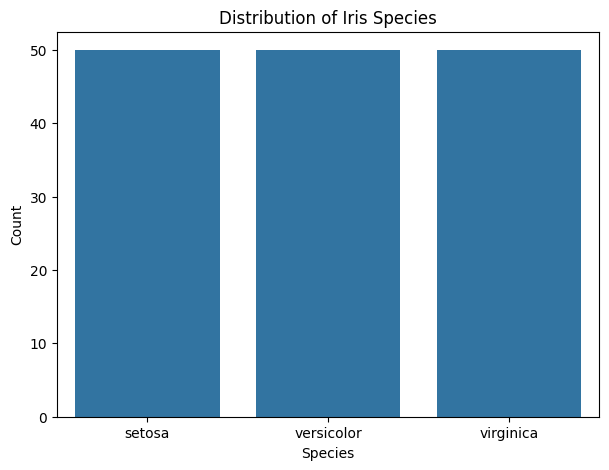

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="species_name"
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.savefig("../outputs/species_distribution.png")
plt.show()

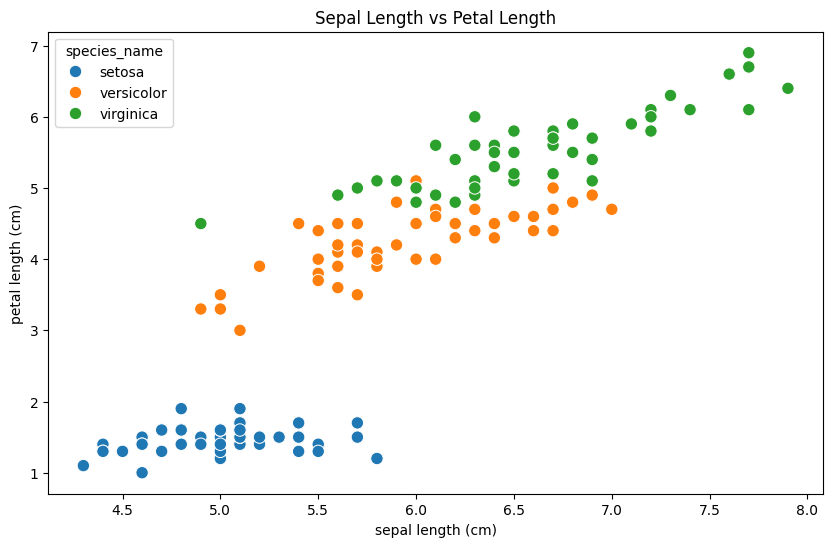

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="petal length (cm)",
    hue="species_name",
    s=80
)

plt.title("Sepal Length vs Petal Length")
plt.savefig("../outputs/sepal_vs_petal.png")
plt.show()

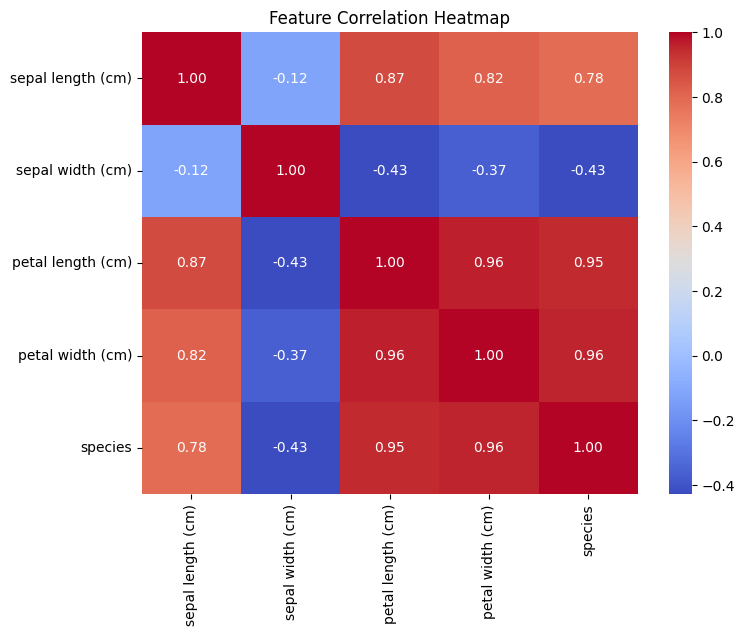

In [17]:
plt.figure(figsize=(8, 6))

correlation = df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.savefig("../outputs/correlation_heatmap.png")
plt.show()

In [18]:
# Separate input features and target variable

X = df[iris.feature_names]
y = df["species"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Feature shape: (150, 4)
Target shape: (150,)

Input features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target values:
0    0
1    0
2    0
3    0
4    0
Name: species, dtype: int64


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test.value_counts().sort_index())

Training samples: 120
Testing samples: 30

Training distribution:
species
0    40
1    40
2    40
Name: count, dtype: int64

Testing distribution:
species
0    10
1    10
2    10
Name: count, dtype: int64


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature scaling completed!
Scaled training shape: (120, 4)
Scaled testing shape: (30, 4)


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Initialize models
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "SVM": SVC(kernel="rbf")
}

# Train models
trained_models = {}

for name, model in models.items():

    # Use scaled data for scale-sensitive models
    if name in ["Logistic Regression", "KNN", "SVM"]:
        model.fit(X_train_scaled, y_train)
    else:
        model.fit(X_train, y_train)

    trained_models[name] = model

    print(name, "training completed!")
    

Logistic Regression training completed!
KNN training completed!
Decision Tree training completed!
Random Forest training completed!
SVM training completed!


In [22]:
from sklearn.metrics import accuracy_score, classification_report

results = []

for name, model in trained_models.items():

    if name in ["Logistic Regression", "KNN", "SVM"]:
        predictions = model.predict(X_test_scaled)
    else:
        predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(f"\n{name}")
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(classification_report(
        y_test,
        predictions,
        target_names=iris.target_names
    ))

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(results_df.sort_values(
    by="Accuracy",
    ascending=False
).to_string(index=False))

























































Logistic Regression
Accuracy: 93.33%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


KNN
Accuracy: 93.33%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


Decision Tree
Accuracy: 93.33%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90    

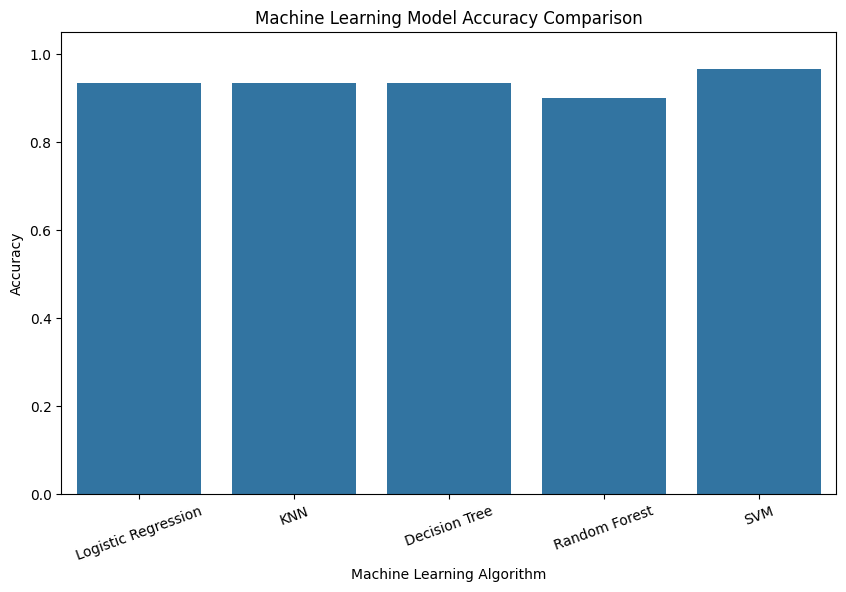

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)

plt.savefig(
    "../outputs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
best_model_name = results_df.sort_values(
    by="Accuracy",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: SVM


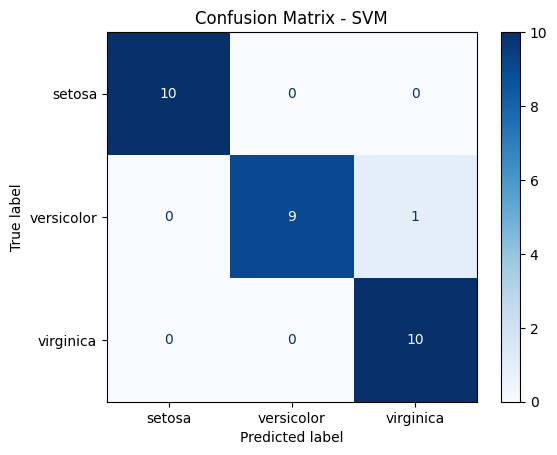

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

if best_model_name in ["Logistic Regression", "KNN", "SVM"]:
    y_pred = best_model.predict(X_test_scaled)
else:
    y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")

plt.title(f"Confusion Matrix - {best_model_name}")
plt.savefig(
    "../outputs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [26]:
# Example flower measurements
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

# Apply scaling if required
if best_model_name in ["Logistic Regression", "KNN", "SVM"]:
    new_flower_input = scaler.transform(new_flower)
else:
    new_flower_input = new_flower

# Predict species
prediction = best_model.predict(new_flower_input)

predicted_species = iris.target_names[prediction[0]]

print("Predicted Iris Species:", predicted_species)

Predicted Iris Species: setosa


In [27]:
import joblib
import os

os.makedirs("../outputs", exist_ok=True)

joblib.dump(
    best_model,
    "../outputs/iris_model.pkl"
)

joblib.dump(
    scaler,
    "../outputs/scaler.pkl"
)

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
